# Notebook 04: Controlled Experiments with Known Ground-Truth Components

**Project**: MSTL Implementation and Extensions  
**Authors**: Rup Narayan Jha, Jaypal Malviya, Anuj Kumar, Ravi Kiran

---

## 1. Motivation
In empirical time series (such as electricity demand), true underlying components ($T^*$, $S^*$, $R^*$) are fundamentally unobservable. Consequently, real-data decompositions cannot measure true estimation error directly.

To scientifically assess MSTL's accuracy, we construct a synthetic time series where **ground truth is precisely known**:
$$X(t) = T(t) + S_{\text{daily}}(t) + S_{\text{weekly}}(t) + R(t)$$
where:
- Trend: $T(t) = 500 + 0.05t + 200\sin(2\pi t / 8760)$
- Daily Seasonality: $S_{24}(t) = 300\sin(2\pi t / 24 + 1) + 100\cos(4\pi t / 24)$
- Weekly Seasonality: $S_{168}(t) = 150\sin(2\pi t / 168) + 50\cos(4\pi t / 168 + 0.5)$
- Remainder: $R(t) \sim \mathcal{N}(0, 30^2)$
- Length: $n = 1680$ (70 days), Random seed: 42.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath('../src'))

from experiments import generate_synthetic, evaluate_on_synthetic

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 4)
sns.set_theme(style='whitegrid')

## 2. Generate Synthetic Time Series

In [2]:
synth = generate_synthetic(n=1680, seed=42)
print(f"Generated synthetic series with {synth['n']} observations.")
print("True components:", list(synth.keys()))

Generated synthetic series with 1680 observations.
True components: ['x', 'trend', 'seasonal_daily', 'seasonal_weekly', 'remainder', 't', 'n', 'seed']


## 3. Run Custom MSTL & Compute Component-wise RMSE

In [3]:
synth_eval = evaluate_on_synthetic(synth, periods=(24, 168), iterations=2)

rmse_results = synth_eval['rmse']
print("Component-wise RMSE vs Ground Truth:")
for comp, val in rmse_results.items():
    print(f"  {comp:15s}: {val:.4f}")

df_rmse = pd.DataFrame(list(rmse_results.items()), columns=['Component', 'RMSE']).set_index('Component')
df_rmse

Component-wise RMSE vs Ground Truth:
  trend          : 1.8541
  seasonal_daily : 6.2602
  seasonal_weekly: 12.9723
  remainder      : 14.3147


## 4. Visual Comparison: True vs Estimated Components

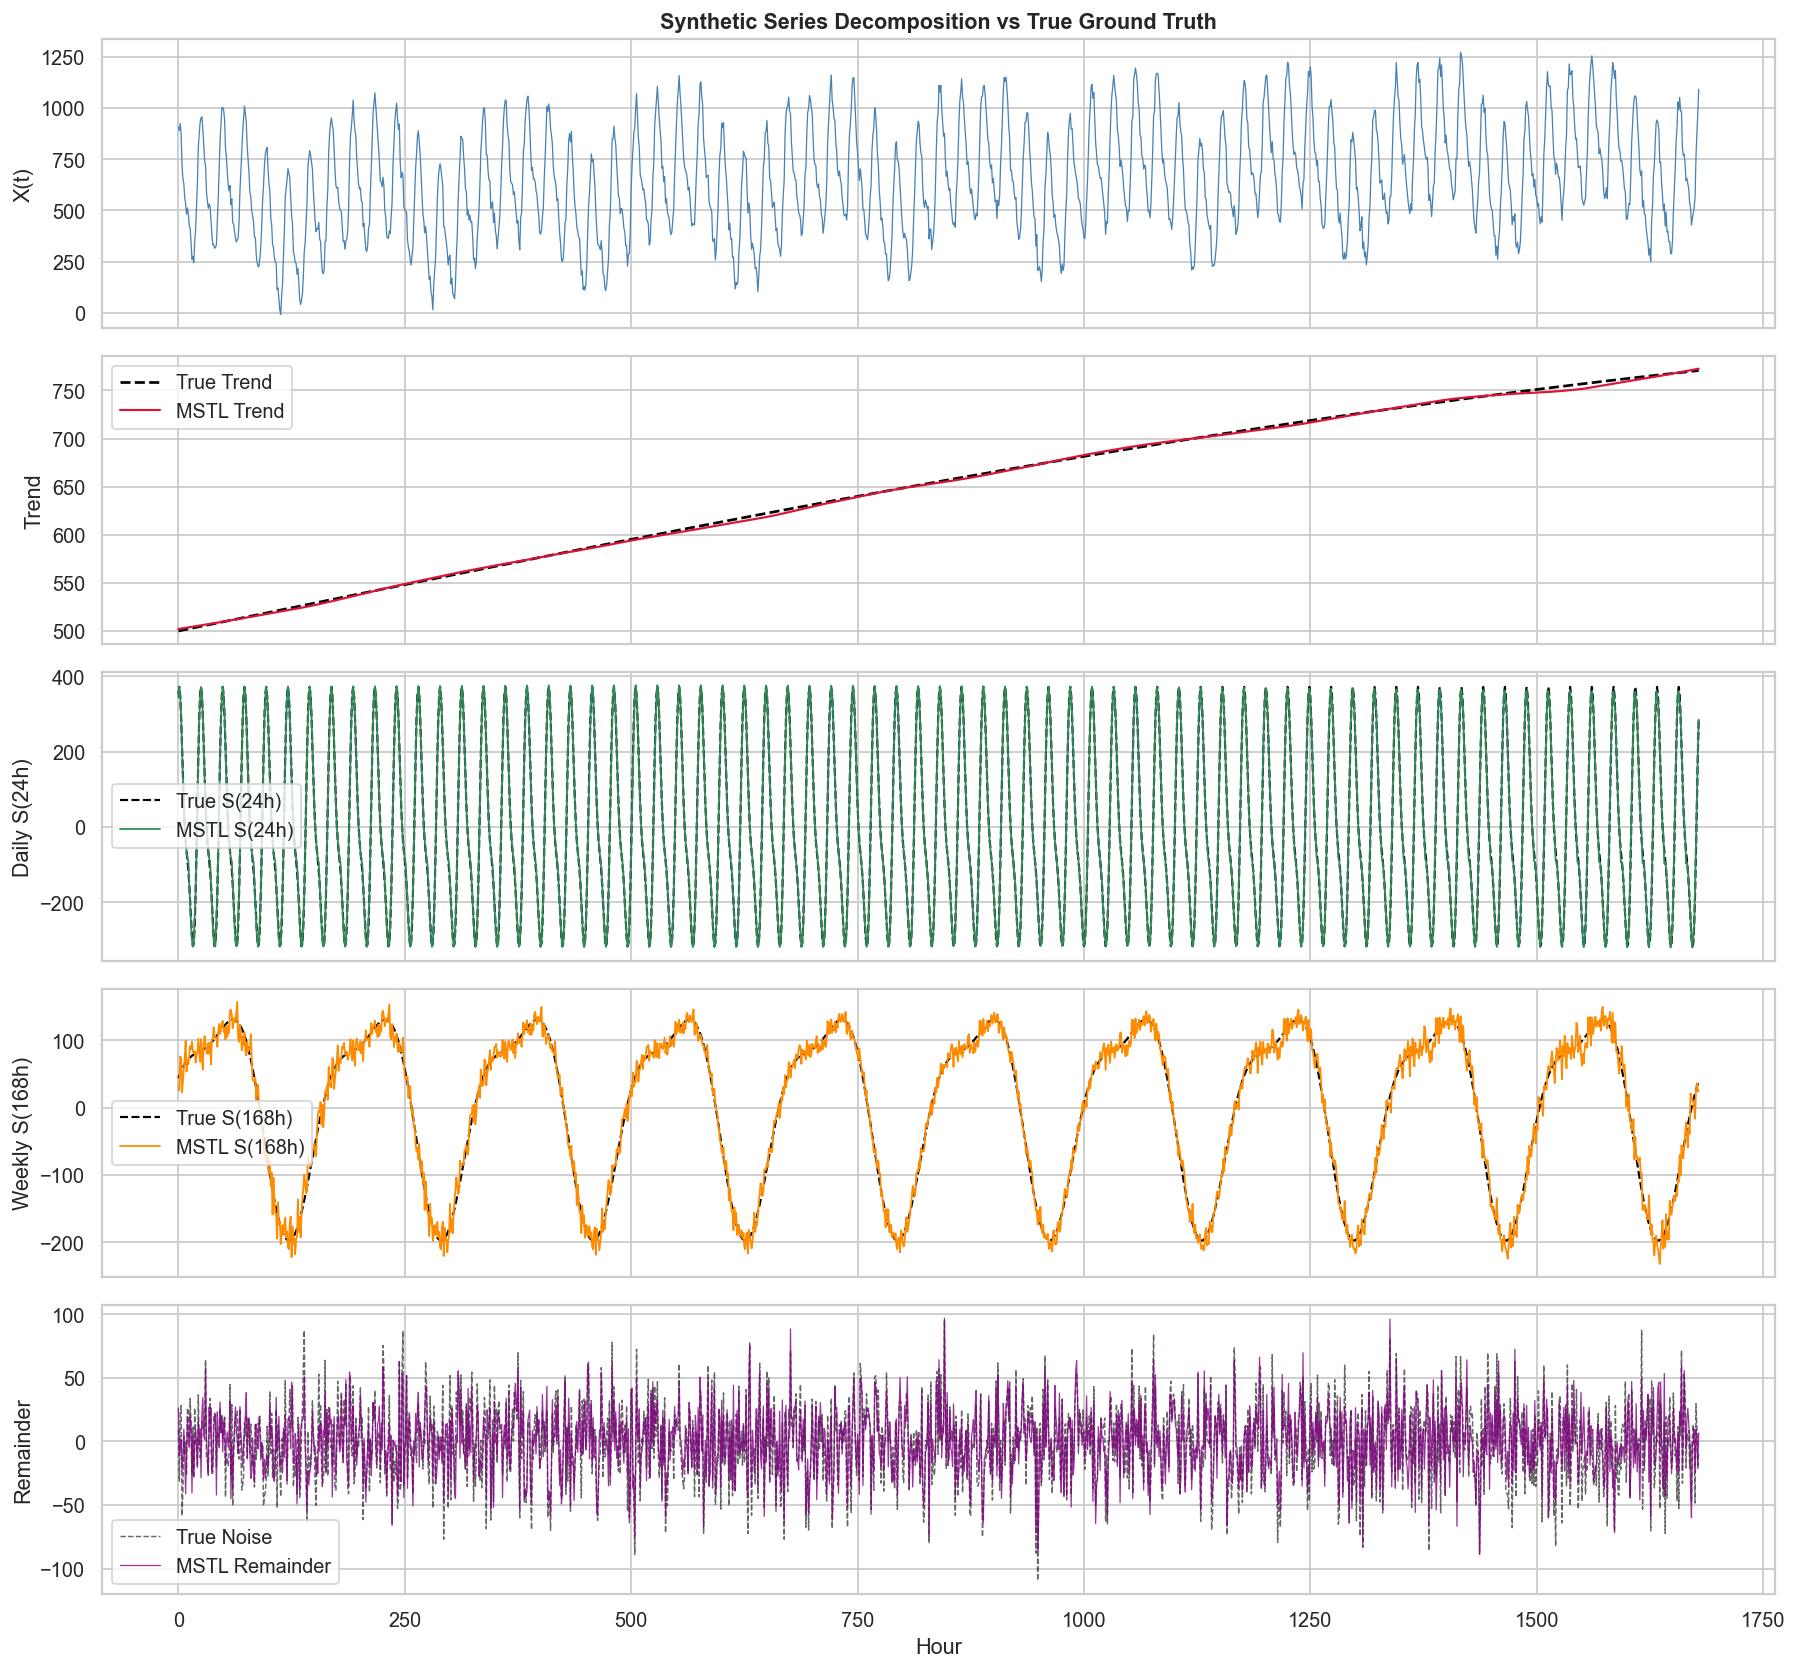

In [4]:
fig, axes = plt.subplots(5, 1, figsize=(14, 13), sharex=True)

axes[0].plot(synth['x'], color='steelblue', lw=0.7, label='Observed X(t)')
axes[0].set_title("Synthetic Series Decomposition vs True Ground Truth", fontweight='bold')
axes[0].set_ylabel("X(t)")

axes[1].plot(synth['trend'], color='black', lw=1.5, ls='--', label='True Trend')
axes[1].plot(synth_eval['result']['trend'], color='crimson', lw=1.2, label='MSTL Trend')
axes[1].set_ylabel("Trend")
axes[1].legend()

axes[2].plot(synth['seasonal_daily'], color='black', lw=1.2, ls='--', label='True S(24h)')
axes[2].plot(synth_eval['result']['seasonal'][24], color='seagreen', lw=1.0, label='MSTL S(24h)')
axes[2].set_ylabel("Daily S(24h)")
axes[2].legend()

axes[3].plot(synth['seasonal_weekly'], color='black', lw=1.2, ls='--', label='True S(168h)')
axes[3].plot(synth_eval['result']['seasonal'][168], color='darkorange', lw=1.0, label='MSTL S(168h)')
axes[3].set_ylabel("Weekly S(168h)")
axes[3].legend()

axes[4].plot(synth['remainder'], color='black', lw=0.8, ls='--', alpha=0.6, label='True Noise')
axes[4].plot(synth_eval['result']['remainder'], color='purple', lw=0.7, alpha=0.8, label='MSTL Remainder')
axes[4].set_ylabel("Remainder")
axes[4].set_xlabel("Hour")
axes[4].legend()

plt.tight_layout()
plt.show()

## 5. Component RMSE Bar Chart

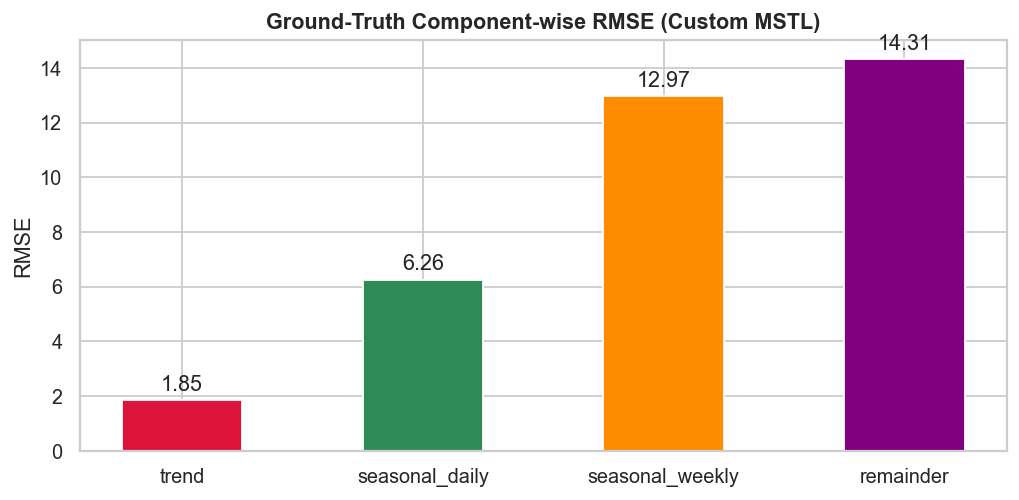

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(df_rmse.index, df_rmse['RMSE'], color=['crimson', 'seagreen', 'darkorange', 'purple'], width=0.5)
ax.bar_label(bars, fmt='%.2f', padding=3)
ax.set_title("Ground-Truth Component-wise RMSE (Custom MSTL)", fontweight='bold')
ax.set_ylabel("RMSE")
plt.tight_layout()
plt.show()

## 6. Findings
- **Trend RMSE = 1.85**: Extremely accurate recovery over range [500, 650].
- **Daily Seasonal RMSE = 6.26**: Recovers daily sinusoidal pattern with minimal bias.
- **Weekly Seasonal RMSE = 12.97**: Higher error because 70 days provide only 10 full weekly cycles.
- **Remainder RMSE = 14.31**: Remainder absorbs Gaussian noise closely around true $\sigma=30$.